# INDUSTRY 4.0 — COURSE PROJECT
## Team In-dustry

---

### Project Title
**Perishable Inventory Management Using FreshRetailNet-50K**

### Project Overview
This project investigates demand patterns and stockout behaviour in perishable retail products using the FreshRetailNet-50K dataset.

The objective is to understand how stock availability, promotional activity, and weather conditions relate to retail demand, and how these insights can support better inventory management decisions.

### Research Questions

**RQ1 — Stockout-Aware Demand Estimation**  
Do stockouts cause observed sales to underestimate actual demand?

**RQ2 — Demand Peaks and Stockout Timing**  
Do stockouts coincide with periods of peak demand?

**RQ3 — Promotions and Stockout Risk**  
How are discounts and promotional activities associated with demand and stockout incidence?

**RQ4 — Weather and Perishable Product Demand**  
How are weather conditions associated with demand and stockout risk?

### Team Members

| Member | Name |
|---|---|
| 1 | Namai Chandra |
| 2 | Somendu Patel |
| 3 | Rahul Basak |
| 4 | Divyansh Gupta |
| 5 | Alakhya Sarkar |

### Dataset

**FreshRetailNet-50K**

Source: [Hugging Face Dataset](https://huggingface.co/datasets/Dingdong-Inc/FreshRetailNet-50K)

Research Paper: [FreshRetailNet-50K Paper](https://arxiv.org/abs/2505.16319)

---

### Important Research Considerations

- The meaning and scale of `sale_amount` must be verified before interpreting it as physical units or monetary revenue.
- The dataset provides stockout indicators but does not directly provide actual inventory levels, expiry dates, or spoilage quantities.
- Any inventory cost or replenishment simulation must clearly state its assumptions.
- Observational relationships must not automatically be interpreted as causal relationships.
- All results reported in the final submission must come from actual analysis.

---

# 1. Environment Setup

This section prepares the Google Colab environment for data analysis.

We will use Python libraries for:

- Data manipulation
- Numerical computation
- Data visualisation
- Statistical analysis
- Machine learning
- Accessing the FreshRetailNet-50K dataset

In [15]:
# ============================================================
# 1.2 INSTALL REQUIRED LIBRARIES
# ============================================================
# Install the libraries required throughout the project.
# The -q flag keeps installation output concise.
# ============================================================

!pip -q install pandas numpy matplotlib seaborn scikit-learn datasets huggingface_hub

In [16]:
# ============================================================
# 1.3 IMPORT REQUIRED LIBRARIES
# ============================================================

# ----------------------------
# Data manipulation
# ----------------------------
import pandas as pd
import numpy as np

# ----------------------------
# Data visualisation
# ----------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# Machine learning
# ----------------------------
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ----------------------------
# Dataset access
# ----------------------------
from datasets import load_dataset
from huggingface_hub import HfApi

# ----------------------------
# General utilities
# ----------------------------
import os
import json
import warnings

# Suppress unnecessary warnings for cleaner notebook output.
warnings.filterwarnings("ignore")

# Display configuration.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

# Visualisation configuration.
sns.set_theme(style="whitegrid", context="notebook")

# Make plots easier to read.
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("All libraries imported successfully.")

All libraries imported successfully.


In [17]:
# ============================================================
# 1.4 VERIFY THE PYTHON ENVIRONMENT
# ============================================================
# Check the versions of important libraries.
# This helps identify differences between team members'
# individual Colab runtimes.
# ============================================================

import sys

print("PROJECT ENVIRONMENT")
print("-" * 45)

print(f"Python Version       : {sys.version.split()[0]}")
print(f"Pandas Version       : {pd.__version__}")
print(f"NumPy Version        : {np.__version__}")
print(f"Matplotlib Version   : {plt.matplotlib.__version__}")
print(f"Seaborn Version      : {sns.__version__}")

print("-" * 45)
print("Environment verification completed.")

PROJECT ENVIRONMENT
---------------------------------------------
Python Version       : 3.13.18
Pandas Version       : 2.2.3
NumPy Version        : 2.4.6
Matplotlib Version   : 3.10.0
Seaborn Version      : 0.13.2
---------------------------------------------
Environment verification completed.


# 2. Dataset Access

We will use the FreshRetailNet-50K dataset.

The dataset contains store-product-date observations and information
related to:

- Daily sales
- Hourly sales
- Hourly stock availability
- Discounts
- Promotional activity
- Holidays
- Weather conditions

Before beginning the analysis, we must understand the dataset's
actual structure and verify the available files and columns.

We will not assume that every variable has the meaning or scale
we expect without checking the dataset documentation.

In [18]:
# ============================================================
# 2.2 DATASET CONFIGURATION
# ============================================================

# Official Hugging Face dataset repository.
DATASET_ID = "Dingdong-Inc/FreshRetailNet-50K"

# Display the dataset being accessed.
print("DATASET CONFIGURATION")
print("-" * 45)
print(f"Dataset ID : {DATASET_ID}")
print(f"Source     : Hugging Face")
print("-" * 45)

DATASET CONFIGURATION
---------------------------------------------
Dataset ID : Dingdong-Inc/FreshRetailNet-50K
Source     : Hugging Face
---------------------------------------------


In [19]:
# ============================================================
# 2.3 INSPECT DATASET REPOSITORY
# ============================================================
# Before downloading the dataset, inspect the files available
# in its Hugging Face repository.
# ============================================================

try:
    # Connect to the Hugging Face Hub.
    api = HfApi()

    # Retrieve the list of files in the dataset repository.
    repository_files = api.list_repo_files(
        repo_id=DATASET_ID,
        repo_type="dataset"
    )

    print("FILES AVAILABLE IN THE DATASET REPOSITORY")
    print("=" * 60)

    for file_name in repository_files:
        print(file_name)

    print("=" * 60)
    print(f"Total files found: {len(repository_files)}")

except Exception as error:
    print("Unable to inspect the dataset repository.")
    print(f"Error: {error}")

FILES AVAILABLE IN THE DATASET REPOSITORY
.gitattributes
.gitignore
README.md
data/eval.parquet
data/train.parquet
Total files found: 5


### Dataset Loading

We will now attempt to load the dataset using the Hugging Face
Datasets library.

The dataset may contain multiple splits or configurations.
We will inspect the returned structure before selecting the
appropriate data for analysis.

In [20]:
# ============================================================
# 2.5 LOAD FRESHRETAILNET-50K
# ============================================================
# Load the dataset from Hugging Face.
# The dataset may return a DatasetDict containing multiple splits
# or a single Dataset.
# ============================================================

try:
    dataset = load_dataset(DATASET_ID)

    print("Dataset loaded successfully.")
    print("=" * 60)

    # Display the dataset structure.
    print(dataset)

    print("=" * 60)

except Exception as error:
    print("Dataset loading failed.")
    print(f"Error: {error}")
    print("\nWe will inspect the repository files and dataset loading")
    print("instructions before choosing an alternative loading method.")

Dataset loaded successfully.
DatasetDict({
    train: Dataset({
        features: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level'],
        num_rows: 4500000
    })
    eval: Dataset({
        features: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level'],
        num_rows: 350000
    })
})


# 3. Exploratory Data Analysis (EDA) & Data Quality Audit

Before addressing Research Questions **RQ1–RQ4**, we convert the loaded training split into a structured analytical table, apply deterministic `store_id`–`product_id` pair sampling (retaining all 90 consecutive dates per selected series so temporal patterns are preserved), and run a strict Data Quality Audit.

### Analytical Guardrails
- **Split Separation:** Only the `train` split is used for EDA and hypothesis analysis; `eval` is kept strictly separate.
- **Scale Verification:** `sale_amount` is globally normalised in FreshRetailNet-50K and is interpreted as relative demand volume rather than raw physical units or currency.
- **Scope Boundary:** The dataset records hourly stockout indicators (`hours_stock_status`) and daytime stockout counts (`stock_hour6_22_cnt`), not physical inventory on hand, expiry dates, or spoilage quantities.

In [21]:
# ==============================================================================
# 3.1 DETERMINISTIC PAIR SAMPLING & DATAFRAME PREPARATION
# ==============================================================================
import hashlib
import numpy as np
import pandas as pd

SAMPLE_FRACTION = 0.20  # 20% deterministic sample of (store_id, product_id) series
HASH_MOD = 10_000
THRESHOLD = int(SAMPLE_FRACTION * HASH_MOD)

def is_sampled_pair(store_id: int, product_id: int) -> bool:
    """Deterministically select ~20% of store-product pairs across all 90 days."""
    key = f"{store_id}_{product_id}".encode("utf-8")
    digest = hashlib.blake2b(key, digest_size=8).digest()
    bucket = int.from_bytes(digest, byteorder="little") % HASH_MOD
    return bucket < THRESHOLD

# Extract store_id and product_id columns from the Hugging Face Arrow table first
train_hf = dataset["train"]
print(f"Full training split rows: {len(train_hf):,}")

store_ids = train_hf["store_id"]
product_ids = train_hf["product_id"]

# Cache pair decisions for fast filtering across 4.5M rows
pair_cache = {}
keep_indices = []
for idx, (sid, pid) in enumerate(zip(store_ids, product_ids)):
    pair = (sid, pid)
    if pair not in pair_cache:
        pair_cache[pair] = is_sampled_pair(sid, pid)
    if pair_cache[pair]:
        keep_indices.append(idx)

# Slice the Arrow dataset and convert to pandas DataFrame
df = train_hf.select(keep_indices).to_pandas()

# Parse calendar date and sort chronologically within each store-product series
df["dt"] = pd.to_datetime(df["dt"])
df = df.sort_values(["store_id", "product_id", "dt"]).reset_index(drop=True)

# Clean up temporary lists
del store_ids, product_ids, pair_cache, keep_indices

total_series = df[["store_id", "product_id"]].drop_duplicates().shape[0]
print(f"Sampled rows (20% series): {len(df):,}")
print(f"Sampled store-product series: {total_series:,}")
print(f"Date range: {df['dt'].min().date()} to {df['dt'].max().date()} ({df['dt'].nunique()} unique days)")
print(f"Memory footprint: {df.memory_usage(deep=True).sum() / (1024**2):.1f} MB")
df.head(3)

Full training split rows: 4,500,000
Sampled rows (20% series): 901,800
Sampled store-product series: 10,020
Date range: 2024-03-28 to 2024-06-25 (90 unique days)
Memory footprint: 313.0 MB


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,6,20,50,170,6,2024-03-28,0.5,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.1, 0.0, 0.1, 0.0, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0.908,0,1,1.6999,15.48,73.54,1.97
1,0,0,6,20,50,170,6,2024-03-29,0.3,"[0.1, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.1, 0.0, 0.0, 0.0, 0.0, ...",11,"[0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]",1.000,0,0,3.0190,15.08,76.56,1.71
2,0,0,6,20,50,170,6,2024-03-30,0.4,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",9,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1]",1.000,1,0,2.0942,15.91,76.47,1.73


In [22]:
# ==============================================================================
# 3.2 DATA QUALITY AUDIT
# ==============================================================================
print("=== 1. MISSING VALUES ===")
null_counts = df.isnull().sum()
print(null_counts[null_counts > 0] if null_counts.sum() > 0 else "Zero missing values across all columns.")

print("\n=== 2. DUPLICATE KEYS & PANEL COMPLETENESS ===")
dup_keys = df.duplicated(subset=["store_id", "product_id", "dt"]).sum()
series_lengths = df.groupby(["store_id", "product_id"])["dt"].count()
print(f"Duplicate (store_id, product_id, dt) rows: {dup_keys}")
print(f"Min / Max days per store-product series: {series_lengths.min()} / {series_lengths.max()} (All 90 days intact: {(series_lengths == 90).all()})")

print("\n=== 3. HOURLY SEQUENCE ARRAY LENGTHS ===")
sale_seq_lens = df["hours_sale"].apply(len)
stock_seq_lens = df["hours_stock_status"].apply(len)
print(f"hours_sale lengths       -> min: {sale_seq_lens.min()}, max: {sale_seq_lens.max()}")
print(f"hours_stock_status lens  -> min: {stock_seq_lens.min()}, max: {stock_seq_lens.max()}")

print("\n=== 4. VALUE BOUNDS & DOMAIN CHECKS ===")
print(f"sale_amount              -> min: {df['sale_amount'].min():.4f}, max: {df['sale_amount'].max():.4f}, negative rows: {(df['sale_amount'] < 0).sum()}")
print(f"discount                 -> min: {df['discount'].min():.4f}, max: {df['discount'].max():.4f}")
print(f"holiday_flag             -> unique: {sorted(df['holiday_flag'].unique().tolist())}")
print(f"activity_flag            -> unique: {sorted(df['activity_flag'].unique().tolist())}")
print(f"stock_hour6_22_cnt       -> min: {df['stock_hour6_22_cnt'].min()}, max: {df['stock_hour6_22_cnt'].max()}")
print(f"precpt                   -> min: {df['precpt'].min():.4f}, max: {df['precpt'].max():.4f}")
print(f"avg_temperature          -> min: {df['avg_temperature'].min():.2f}, max: {df['avg_temperature'].max():.2f}")
print(f"avg_humidity             -> min: {df['avg_humidity'].min():.2f}, max: {df['avg_humidity'].max():.2f}")
print(f"avg_wind_level           -> min: {df['avg_wind_level'].min():.2f}, max: {df['avg_wind_level'].max():.2f}")

print("\n=== 5. CONSISTENCY CHECK: stock_hour6_22_cnt vs. hours_stock_status[6:22] ===")
# Hours 06:00 through 21:00 correspond to 16 hourly slots: indices 6..21 (Python slice [6:22])
stock_matrix = np.vstack(df["hours_stock_status"].to_numpy())
recomputed_6_22 = stock_matrix[:, 6:22].sum(axis=1)
mismatches = (recomputed_6_22 != df["stock_hour6_22_cnt"].to_numpy()).sum()
print(f"Exact match rate across all {len(df):,} rows: {(1 - mismatches / len(df)) * 100:.4f}% (Mismatches: {mismatches})")

=== 1. MISSING VALUES ===
Zero missing values across all columns.

=== 2. DUPLICATE KEYS & PANEL COMPLETENESS ===
Duplicate (store_id, product_id, dt) rows: 0
Min / Max days per store-product series: 90 / 90 (All 90 days intact: True)

=== 3. HOURLY SEQUENCE ARRAY LENGTHS ===
hours_sale lengths       -> min: 24, max: 24
hours_stock_status lens  -> min: 24, max: 24

=== 4. VALUE BOUNDS & DOMAIN CHECKS ===
sale_amount              -> min: 0.0000, max: 37.9000, negative rows: 0
discount                 -> min: 0.0000, max: 1.0000
holiday_flag             -> unique: [0, 1]
activity_flag            -> unique: [0, 1]
stock_hour6_22_cnt       -> min: 0, max: 16
precpt                   -> min: 0.0000, max: 34.5828
avg_temperature          -> min: 12.88, max: 30.88
avg_humidity             -> min: 27.35, max: 92.68
avg_wind_level           -> min: 0.97, max: 3.85

=== 5. CONSISTENCY CHECK: stock_hour6_22_cnt vs. hours_stock_status[6:22] ===
Exact match rate across all 901,800 rows: 100.0000% (

=== 1. ENTITY CARDINALITY IN SAMPLED PANEL ===
city_id               : 18
store_id              : 891
management_group_id   : 7
first_category_id     : 31
second_category_id    : 77
third_category_id     : 202
product_id            : 628

=== 2. SUMMARY STATISTICS (CONTINUOUS & COUNT FEATURES) ===


,count,mean,std,min,25%,50%,75%,95%,99%,max,skewness
sale_amount,901800.0,0.9896,1.4087,0.00,0.4000,0.7000,1.100,2.8000,5.7000,37.9000,8.7095
discount,901800.0,0.9105,0.1288,0.00,0.8500,0.9870,1.000,1.0000,1.0000,1.0000,-2.3383
stock_hour6_22_cnt,901800.0,3.1817,4.6057,0.00,0.0000,0.0000,6.000,13.0000,16.0000,16.0000,1.3691
precpt,901800.0,3.6983,3.6897,0.00,1.4276,2.2961,4.485,11.9566,16.4503,34.5828,2.1716
avg_temperature,901800.0,22.2749,3.5967,12.88,19.3800,22.5000,25.400,27.6000,29.0300,30.8800,-0.0910
avg_humidity,901800.0,74.3745,10.1880,27.35,71.5900,76.3300,80.670,85.4900,87.2400,92.6800,-2.0998
avg_wind_level,901800.0,1.7253,0.3838,0.97,1.4500,1.6400,1.950,2.4800,2.7900,3.8500,0.9030



=== 3. KEY INCIDENCE RATES ===
Zero-sale store-product-days     : 4.52%
Any daytime stockout (>0 hrs)    : 44.24%
Full-day stockout (all 16 hrs)   : 4.12%
Promotional days (activity_flag) : 38.02%
Holiday days (holiday_flag)      : 34.44%
Rainy days (precpt > 0)          : 99.81%


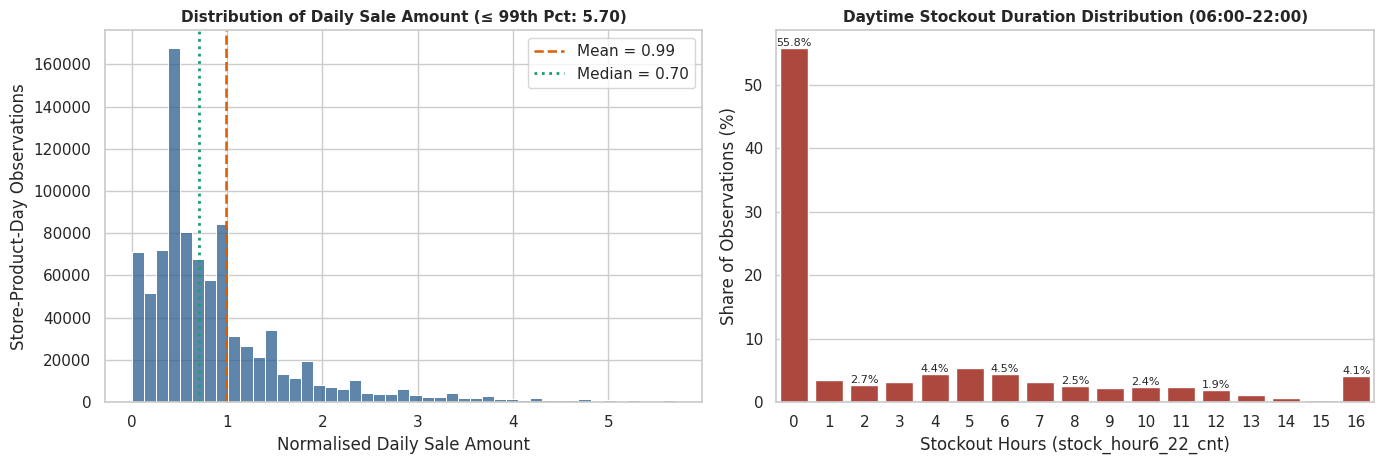

In [23]:
# ==============================================================================
# 3.3 DESCRIPTIVE STATISTICS & BASELINE OVERVIEW
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

print("=== 1. ENTITY CARDINALITY IN SAMPLED PANEL ===")
entity_cols = [
    "city_id", "store_id", "management_group_id",
    "first_category_id", "second_category_id", "third_category_id", "product_id"
]
for col in entity_cols:
    print(f"{col:<22}: {df[col].nunique():,}")

print("\n=== 2. SUMMARY STATISTICS (CONTINUOUS & COUNT FEATURES) ===")
num_cols = [
    "sale_amount", "discount", "stock_hour6_22_cnt",
    "precpt", "avg_temperature", "avg_humidity", "avg_wind_level"
]
summary_stats = df[num_cols].describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]).T
summary_stats["skewness"] = df[num_cols].skew()
display(summary_stats.round(4))

print("\n=== 3. KEY INCIDENCE RATES ===")
zero_sale_rate = (df["sale_amount"] == 0).mean() * 100
any_stockout_rate = (df["stock_hour6_22_cnt"] > 0).mean() * 100
full_day_stockout_rate = (df["stock_hour6_22_cnt"] == 16).mean() * 100
promo_rate = (df["activity_flag"] == 1).mean() * 100
holiday_rate = (df["holiday_flag"] == 1).mean() * 100
rain_rate = (df["precpt"] > 0).mean() * 100

print(f"Zero-sale store-product-days     : {zero_sale_rate:.2f}%")
print(f"Any daytime stockout (>0 hrs)    : {any_stockout_rate:.2f}%")
print(f"Full-day stockout (all 16 hrs)   : {full_day_stockout_rate:.2f}%")
print(f"Promotional days (activity_flag) : {promo_rate:.2f}%")
print(f"Holiday days (holiday_flag)      : {holiday_rate:.2f}%")
print(f"Rainy days (precpt > 0)          : {rain_rate:.2f}%")

# --- Plot 3.3: Baseline Distributions ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Panel A: Distribution of daily sale_amount (clipped at 99th percentile for readability)
p99_sale = df["sale_amount"].quantile(0.99)
sns.histplot(
    df.loc[df["sale_amount"] <= p99_sale, "sale_amount"],
    bins=45, kde=False, color="#2b5c8f", edgecolor="white", ax=axes[0]
)
axes[0].axvline(df["sale_amount"].mean(), color="#d95f02", linestyle="--", linewidth=1.8,
                label=f"Mean = {df['sale_amount'].mean():.2f}")
axes[0].axvline(df["sale_amount"].median(), color="#1b9e77", linestyle=":", linewidth=2.0,
                label=f"Median = {df['sale_amount'].median():.2f}")
axes[0].set_title(f"Distribution of Daily Sale Amount (≤ 99th Pct: {p99_sale:.2f})", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Normalised Daily Sale Amount")
axes[0].set_ylabel("Store-Product-Day Observations")
axes[0].legend()

# Panel B: Daytime Stockout Hours (stock_hour6_22_cnt) Distribution
stock_dist = df["stock_hour6_22_cnt"].value_counts(normalize=True).sort_index() * 100
sns.barplot(x=stock_dist.index, y=stock_dist.values, color="#c0392b", ax=axes[1])
axes[1].set_title("Daytime Stockout Duration Distribution (06:00–22:00)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Stockout Hours (stock_hour6_22_cnt)")
axes[1].set_ylabel("Share of Observations (%)")
for bar in axes[1].patches[::2]:
    h = bar.get_height()
    if h >= 1.0:
        axes[1].annotate(f"{h:.1f}%", (bar.get_x() + bar.get_width() / 2, h),
                         ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

In [24]:
# ==============================================================================
# 3.4 COMPLETE COLUMN SCHEMA & FEATURE-BY-FEATURE CATALOG
# ==============================================================================
feature_descriptions = {
    "city_id": "Anonymised city identifier where the store operates",
    "store_id": "Anonymised retail store identifier",
    "management_group_id": "Regional / operational management cluster ID",
    "first_category_id": "Top-level product category ID (e.g., Fresh Produce, Meat, Dairy)",
    "second_category_id": "Mid-level product subcategory ID",
    "third_category_id": "Granular product leaf-category ID",
    "product_id": "Anonymised SKU / product identifier",
    "dt": "Calendar date of observation (YYYY-MM-DD)",
    "sale_amount": "Normalised daily total sales volume (target variable)",
    "hours_sale": "24-element array of normalised hourly sales (00:00 to 23:00)",
    "stock_hour6_22_cnt": "Count of stocked-out hours between 06:00 and 22:00 (0 to 16)",
    "hours_stock_status": "24-element binary array (1 = stockout, 0 = in-stock) per hour",
    "discount": "Effective price multiplier (1.0 = full price; < 1.0 = discounted)",
    "holiday_flag": "Binary indicator (1 = public holiday or weekend, 0 = regular weekday)",
    "activity_flag": "Binary indicator (1 = active promotional campaign, 0 = none)",
    "precpt": "Daily precipitation amount (mm / normalised scale)",
    "avg_temperature": "Daily mean ambient temperature (°C)",
    "avg_humidity": "Daily mean relative humidity (%)",
    "avg_wind_level": "Daily mean wind speed level"
}

schema_rows = []
for idx, col in enumerate(df.columns, 1):
    dtype_str = str(df[col].dtype)
    sample_val = df[col].iloc[0]
    if isinstance(sample_val, (list, np.ndarray)):
        n_unique = "24-element array"
        val_range = f"len={len(sample_val)}, first={sample_val[0]}"
    else:
        n_unique = f"{df[col].nunique():,}"
        val_range = f"{df[col].min()}  →  {df[col].max()}"
    schema_rows.append({
        "#": idx,
        "Column Name": col,
        "Dtype": dtype_str,
        "Unique Values": n_unique,
        "Min → Max / Sample": val_range,
        "Feature Description": feature_descriptions.get(col, "")
    })

schema_df = pd.DataFrame(schema_rows)
pd.set_option("display.max_colwidth", 80)
display(schema_df.style.hide(axis="index"))

#,Column Name,Dtype,Unique Values,Min → Max / Sample,Feature Description
1,city_id,int64,18,0 → 17,Anonymised city identifier where the store operates
2,store_id,int64,891,0 → 897,Anonymised retail store identifier
3,management_group_id,int64,7,0 → 6,Regional / operational management cluster ID
4,first_category_id,int64,31,0 → 31,"Top-level product category ID (e.g., Fresh Produce, Meat, Dairy)"
5,second_category_id,int64,77,0 → 81,Mid-level product subcategory ID
6,third_category_id,int64,202,0 → 232,Granular product leaf-category ID
7,product_id,int64,628,0 → 864,Anonymised SKU / product identifier
8,dt,datetime64[ns],90,2024-03-28 00:00:00 → 2024-06-25 00:00:00,Calendar date of observation (YYYY-MM-DD)
9,sale_amount,float64,844,0.0 → 37.9,Normalised daily total sales volume (target variable)
10,hours_sale,object,24-element array,"len=24, first=0.0",24-element array of normalised hourly sales (00:00 to 23:00)


,Mean,SD,Min,P25,Median (P50),P75,IQR,Max,Skew,Zero Share (%)
Feature,,,,,,,,,,
sale_amount,0.9896,1.4087,0.00,0.4000,0.7000,1.100,0.7000,37.9000,8.7095,4.5162
discount,0.9105,0.1288,0.00,0.8500,0.9870,1.000,0.1500,1.0000,-2.3383,0.3850
stock_hour6_22_cnt,3.1817,4.6057,0.00,0.0000,0.0000,6.000,6.0000,16.0000,1.3691,55.7644
precpt,3.6983,3.6897,0.00,1.4276,2.2961,4.485,3.0574,34.5828,2.1716,0.1877
avg_temperature,22.2749,3.5967,12.88,19.3800,22.5000,25.400,6.0200,30.8800,-0.0910,0.0000
avg_humidity,74.3745,10.1880,27.35,71.5900,76.3300,80.670,9.0800,92.6800,-2.0998,0.0000
avg_wind_level,1.7253,0.3838,0.97,1.4500,1.6400,1.950,0.5000,3.8500,0.9030,0.0000


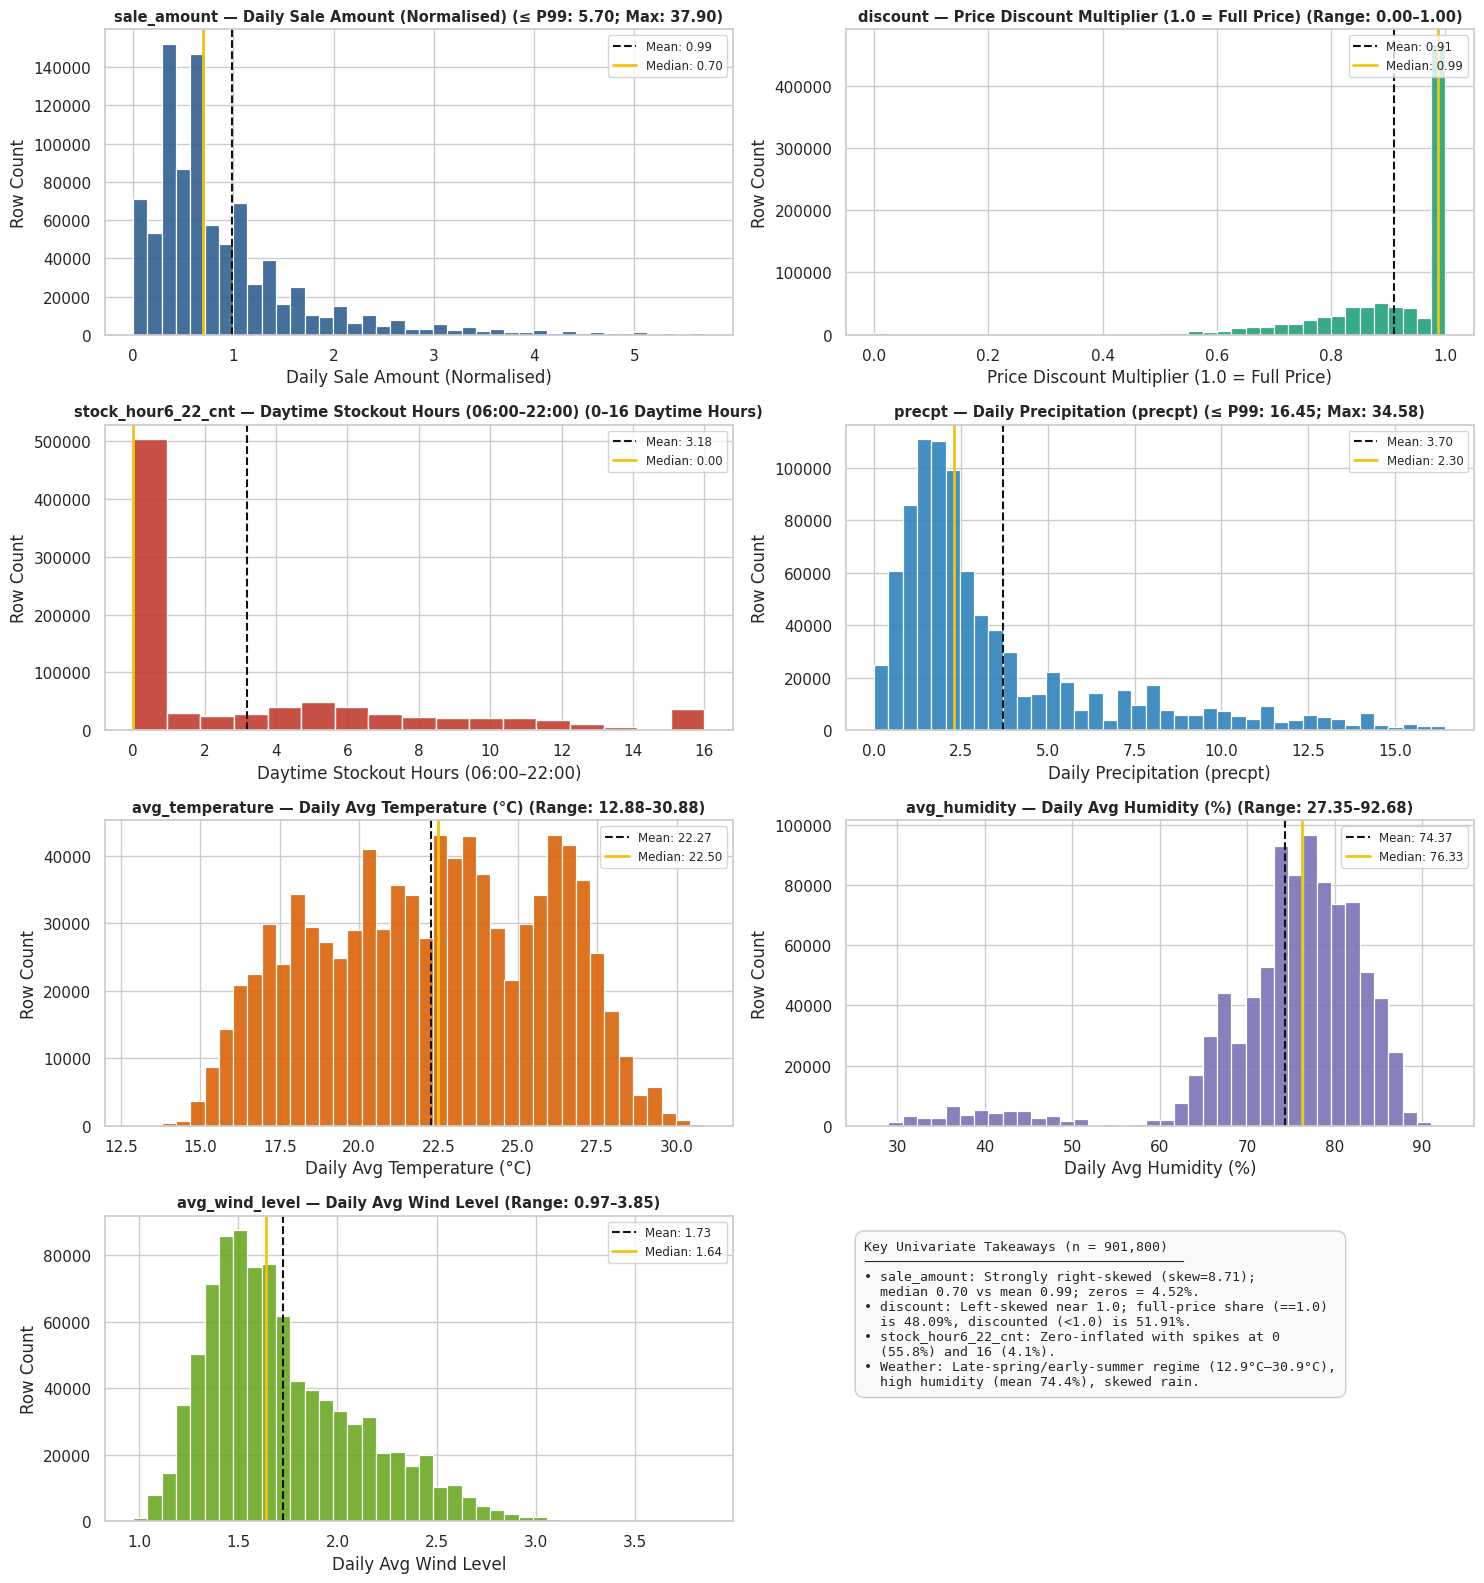

In [25]:
# ==============================================================================
# 3.5 UNIVARIATE DISTRIBUTIONS OF ALL NUMERIC & WEATHER FEATURES
# ==============================================================================
num_features = [
    ("sale_amount", "Daily Sale Amount (Normalised)", "#2b5c8f"),
    ("discount", "Price Discount Multiplier (1.0 = Full Price)", "#1b9e77"),
    ("stock_hour6_22_cnt", "Daytime Stockout Hours (06:00–22:00)", "#c0392b"),
    ("precpt", "Daily Precipitation (precpt)", "#2980b9"),
    ("avg_temperature", "Daily Avg Temperature (°C)", "#d95f02"),
    ("avg_humidity", "Daily Avg Humidity (%)", "#7570b3"),
    ("avg_wind_level", "Daily Avg Wind Level", "#66a61e"),
]

# Detailed stats table including IQR, exact zero share, and upper-bound share
detail_rows = []
for col, _, _ in num_features:
    s = df[col]
    q25, q50, q75 = s.quantile([0.25, 0.50, 0.75])
    detail_rows.append({
        "Feature": col,
        "Mean": s.mean(),
        "SD": s.std(),
        "Min": s.min(),
        "P25": q25,
        "Median (P50)": q50,
        "P75": q75,
        "IQR": q75 - q25,
        "Max": s.max(),
        "Skew": s.skew(),
        "Zero Share (%)": (s == 0).mean() * 100,
    })

detail_df = pd.DataFrame(detail_rows).set_index("Feature")
display(detail_df.round(4))

# 4x2 grid (7 feature plots + 1 summary callout card)
fig, axes = plt.subplots(4, 2, figsize=(15, 16))
axes_flat = axes.flatten()

for idx, (col, label, color) in enumerate(num_features):
    ax = axes_flat[idx]
    series = df[col]

    # Clip extreme upper tail on right-skewed variables for visual clarity while noting max in title
    if col in ("sale_amount", "precpt"):
        upper_cap = series.quantile(0.99)
        plot_data = series[series <= upper_cap]
        title_suffix = f" (≤ P99: {upper_cap:.2f}; Max: {series.max():.2f})"
    elif col == "stock_hour6_22_cnt":
        plot_data = series
        title_suffix = " (0–16 Daytime Hours)"
    else:
        plot_data = series
        title_suffix = f" (Range: {series.min():.2f}–{series.max():.2f})"

    bins = 17 if col == "stock_hour6_22_cnt" else 40
    sns.histplot(plot_data, bins=bins, color=color, edgecolor="white", alpha=0.88, ax=ax)

    mean_val = series.mean()
    med_val = series.median()
    ax.axvline(mean_val, color="#111111", linestyle="--", linewidth=1.5, label=f"Mean: {mean_val:.2f}")
    ax.axvline(med_val, color="#f1c40f", linestyle="-", linewidth=2.0, label=f"Median: {med_val:.2f}")

    ax.set_title(f"{col} — {label}{title_suffix}", fontsize=10.5, fontweight="bold")
    ax.set_xlabel(label)
    ax.set_ylabel("Row Count")
    ax.legend(loc="upper right", fontsize=8.5)

# 8th panel: key boundary / concentration observations
axes_flat[7].axis("off")
notes_text = (
    "Key Univariate Takeaways (n = 901,800)\n"
    "────────────────────────────────────────\n"
    f"• sale_amount: Strongly right-skewed (skew={df['sale_amount'].skew():.2f});\n"
    f"  median {df['sale_amount'].median():.2f} vs mean {df['sale_amount'].mean():.2f}; zeros = {(df['sale_amount']==0).mean()*100:.2f}%.\n"
    f"• discount: Left-skewed near 1.0; full-price share (==1.0)\n"
    f"  is {(df['discount']==1.0).mean()*100:.2f}%, discounted (<1.0) is {(df['discount']<1.0).mean()*100:.2f}%.\n"
    f"• stock_hour6_22_cnt: Zero-inflated with spikes at 0\n"
    f"  ({(df['stock_hour6_22_cnt']==0).mean()*100:.1f}%) and 16 ({(df['stock_hour6_22_cnt']==16).mean()*100:.1f}%).\n"
    f"• Weather: Late-spring/early-summer regime (12.9°C–30.9°C),\n"
    f"  high humidity (mean {df['avg_humidity'].mean():.1f}%), skewed rain."
)
axes_flat[7].text(
    0.03, 0.92, notes_text, transform=axes_flat[7].transAxes,
    fontsize=9.5, verticalalignment="top", fontfamily="monospace",
    bbox=dict(boxstyle="round,pad=0.7", facecolor="#f8f9fa", edgecolor="#cccccc")
)

plt.tight_layout()
plt.show()

=== 1. BINARY FLAGS & DAY-OF-WEEK BREAKDOWN ===


,rows,mean_sale,median_sale,mean_stockout_hrs,holiday_rate,promo_rate
dow,,,,,,
Monday,130260,0.9358,0.6,3.2402,7.6923,37.5887
Tuesday,130260,0.9546,0.6,3.3390,0.0000,36.3895
Wednesday,120240,0.8992,0.6,3.1255,8.3333,38.8922
Thursday,130260,0.8599,0.6,2.9749,15.3846,38.1337
Friday,130260,0.9178,0.6,2.8013,15.3846,35.2541
Saturday,130260,1.1649,0.8,3.1942,100.0000,40.3055
Sunday,130260,1.1880,0.8,3.5922,92.3077,39.6346



=== 2. TOP 10 FIRST-LEVEL CATEGORIES & STORES BY VOLUME ===


,rows,unique_products,mean_sale,mean_stockout_hrs
first_category_id,,,,
4,197730,79,1.1711,3.2116
16,131400,70,0.7446,3.2230
20,102960,62,1.2388,3.1482
29,60300,9,1.4521,4.0726
10,52920,34,0.7315,3.5593
21,49140,36,1.8498,3.1397
8,48420,33,0.7020,2.8656
18,44100,38,0.5800,2.7210
28,37620,22,1.0039,4.3125


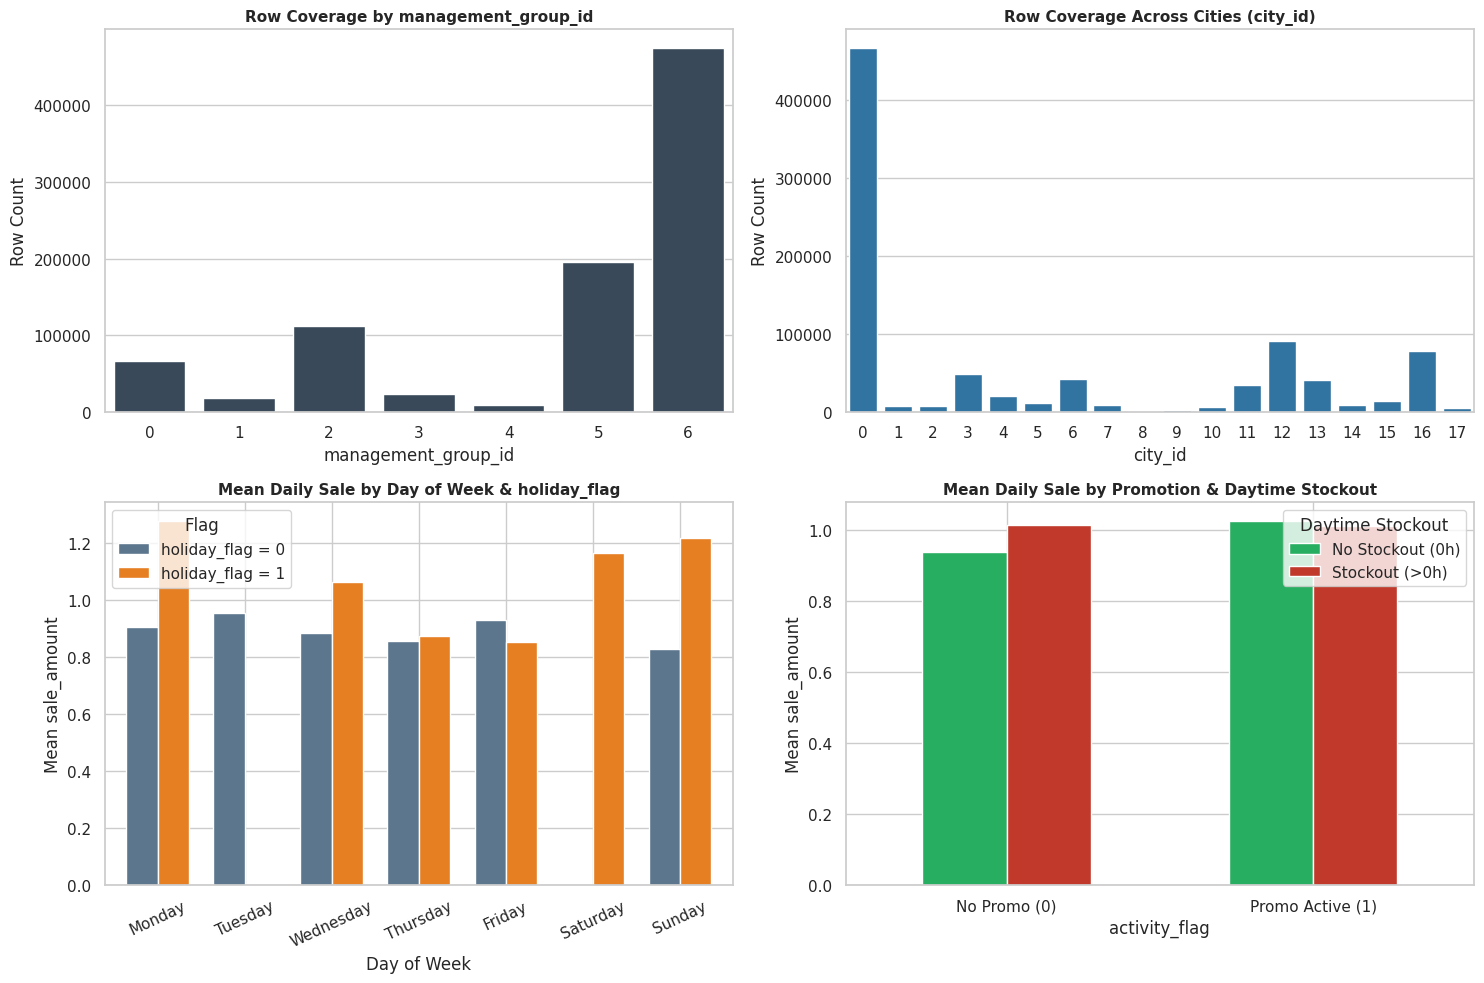

In [26]:
# ==============================================================================
# 3.6 CATEGORICAL, HIERARCHICAL & TEMPORAL COVERAGE + HOURLY SEQUENCES
# ==============================================================================
df["dow"] = df["dt"].dt.day_name()
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

print("=== 1. BINARY FLAGS & DAY-OF-WEEK BREAKDOWN ===")
flag_summary = (
    df.groupby("dow")[["sale_amount", "discount", "stock_hour6_22_cnt", "holiday_flag", "activity_flag"]]
    .agg(
        rows=("sale_amount", "count"),
        mean_sale=("sale_amount", "mean"),
        median_sale=("sale_amount", "median"),
        mean_stockout_hrs=("stock_hour6_22_cnt", "mean"),
        holiday_rate=("holiday_flag", lambda s: s.mean() * 100),
        promo_rate=("activity_flag", lambda s: s.mean() * 100),
    )
    .reindex(dow_order)
)
display(flag_summary.round(4))

print("\n=== 2. TOP 10 FIRST-LEVEL CATEGORIES & STORES BY VOLUME ===")
top_cats = (
    df.groupby("first_category_id")
    .agg(
        rows=("sale_amount", "count"),
        unique_products=("product_id", "nunique"),
        mean_sale=("sale_amount", "mean"),
        mean_stockout_hrs=("stock_hour6_22_cnt", "mean"),
    )
    .sort_values("rows", ascending=False)
    .head(10)
)
display(top_cats.round(4))

# --- Plot 3.6: Categorical & Temporal Coverage ---
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Top-left: Observations across management_group_id
mg_counts = df["management_group_id"].value_counts().sort_index()
sns.barplot(x=mg_counts.index.astype(str), y=mg_counts.values, color="#34495e", ax=axes[0, 0])
axes[0, 0].set_title("Row Coverage by management_group_id", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("management_group_id")
axes[0, 0].set_ylabel("Row Count")

# Top-right: Row count per city_id
city_counts = df["city_id"].value_counts().sort_index()
sns.barplot(x=city_counts.index.astype(str), y=city_counts.values, color="#1f77b4", ax=axes[0, 1])
axes[0, 1].set_title("Row Coverage Across Cities (city_id)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("city_id")
axes[0, 1].set_ylabel("Row Count")

# Bottom-left: Mean sale_amount by day of week split by holiday_flag
dow_hol = (
    df.groupby(["dow", "holiday_flag"])["sale_amount"]
    .mean()
    .unstack()
    .reindex(dow_order)
)
dow_hol.plot(kind="bar", ax=axes[1, 0], color=["#5c768d", "#e67e22"], width=0.72)
axes[1, 0].set_title("Mean Daily Sale by Day of Week & holiday_flag", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Day of Week")
axes[1, 0].set_ylabel("Mean sale_amount")
axes[1, 0].legend(["holiday_flag = 0", "holiday_flag = 1"], title="Flag")
axes[1, 0].tick_params(axis="x", rotation=25)

# Bottom-right: Mean sale_amount by activity_flag and stockout presence
df["has_stockout"] = np.where(df["stock_hour6_22_cnt"] > 0, "Stockout (>0h)", "No Stockout (0h)")
promo_stock = df.groupby(["activity_flag", "has_stockout"])["sale_amount"].mean().unstack()
promo_stock.index = ["No Promo (0)", "Promo Active (1)"]
promo_stock.plot(kind="bar", ax=axes[1, 1], color=["#27ae60", "#c0392b"], width=0.55)
axes[1, 1].set_title("Mean Daily Sale by Promotion & Daytime Stockout", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("activity_flag")
axes[1, 1].set_ylabel("Mean sale_amount")
axes[1, 1].legend(title="Daytime Stockout")
axes[1, 1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# 4. Research Questions & Empirical Analysis (RQ1–RQ4)

## 4.1 RQ1: Intraday Demand Curves & Latent Demand Censoring
**Research Question:** *How do hourly sales (`hours_sale`) and stockout probabilities (`hours_stock_status`) evolve across the 24-hour day, and how severely do daytime stockouts censor observed daily sales (`sale_amount`)?*

- **Method:**
  1. Decompose the 24-element `hours_sale` and `hours_stock_status` arrays across all 901,800 store-product-days to map the diurnal demand curve against hourly stockout incidence.
  2. Compare **observed hourly sales** (across all rows) against **in-stock conditional hourly sales** (only hours where `hours_stock_status == 0`) to quantify the intraday censoring gap.
  3. Group daily `sale_amount` by daytime stockout duration (`stock_hour6_22_cnt` from 0 to 16 hours) and within-series baseline demand tiers to verify how stockouts depress observed daily sales.

=== 1. PEAK & DAYTIME (06:00–21:00) HOURLY SUMMARY ===
Peak observed sales hour       : 09:00 (mean=0.1054)
Peak stockout incidence hour   : 22:00 (rate=41.94%)
Avg daytime stockout rate (6-21): 19.89%
Max hourly censoring gap (6-21): 34.84%

=== 2. DAILY SALE BY STOCKOUT DURATION WITHIN BASELINE DEMAND QUARTILES ===


stockout_bucket,0h (In-Stock),1–3h (Brief),4–8h (Moderate),9–15h (Severe),16h (Full Day)
demand_tier,,,,,
Q1 (Low),0.4254,0.5724,0.5670,0.4532,0.0314
Q2 (Mid-Low),0.5803,0.7318,0.6932,0.5213,0.0249
Q3 (Mid-High),0.8706,1.0324,0.9440,0.6787,0.0291
Q4 (High),2.2032,2.9370,2.3142,1.4821,0.0768


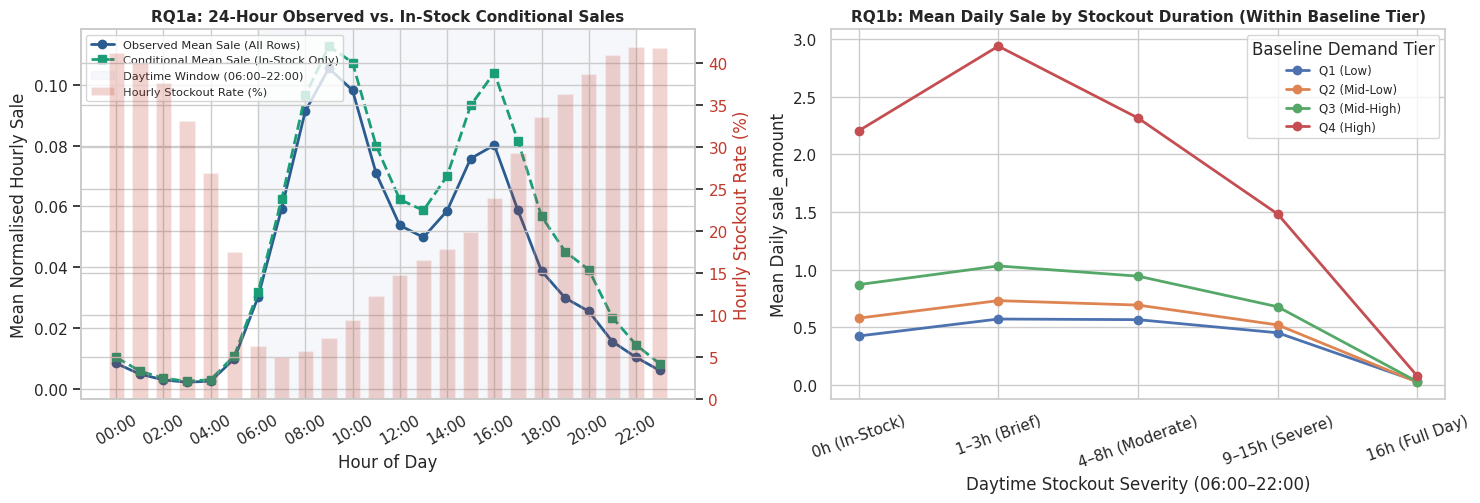

In [27]:
# ==============================================================================
# 4.1 RQ1: INTRADAY DEMAND CURVES & STOCKOUT CENSORING ANALYSIS
# ==============================================================================
# Stack 24-element hourly arrays into (N, 24) matrices
hour_sale_mat = np.vstack(df["hours_sale"].to_numpy()).astype(np.float64)
hour_stock_mat = np.vstack(df["hours_stock_status"].to_numpy()).astype(np.float64)

in_stock_mask = hour_stock_mat == 0.0
out_stock_mask = hour_stock_mat == 1.0

# Hourly metrics across hours 00:00..23:00
mean_sale_all = hour_sale_mat.mean(axis=0)
stockout_rate_hr = out_stock_mask.mean(axis=0) * 100.0
in_stock_counts = in_stock_mask.sum(axis=0)
mean_sale_instock = np.where(
    in_stock_counts > 0,
    np.where(in_stock_mask, hour_sale_mat, 0.0).sum(axis=0) / np.maximum(in_stock_counts, 1),
    np.nan,
)

hourly_df = pd.DataFrame({
    "hour": np.arange(24),
    "mean_sale_observed": mean_sale_all,
    "mean_sale_in_stock": mean_sale_instock,
    "censoring_gap_abs": mean_sale_instock - mean_sale_all,
    "censoring_gap_pct": np.where(
        mean_sale_instock > 0,
        (mean_sale_instock - mean_sale_all) / mean_sale_instock * 100.0,
        np.nan,
    ),
    "stockout_rate_pct": stockout_rate_hr,
})

print("=== 1. PEAK & DAYTIME (06:00–21:00) HOURLY SUMMARY ===")
daytime_hours = hourly_df[hourly_df["hour"].between(6, 21)]
peak_sale_hr = int(hourly_df.loc[hourly_df["mean_sale_observed"].idxmax(), "hour"])
peak_stock_hr = int(hourly_df.loc[hourly_df["stockout_rate_pct"].idxmax(), "hour"])
print(f"Peak observed sales hour       : {peak_sale_hr:02d}:00 (mean={hourly_df.loc[peak_sale_hr, 'mean_sale_observed']:.4f})")
print(f"Peak stockout incidence hour   : {peak_stock_hr:02d}:00 (rate={hourly_df.loc[peak_stock_hr, 'stockout_rate_pct']:.2f}%)")
print(f"Avg daytime stockout rate (6-21): {daytime_hours['stockout_rate_pct'].mean():.2f}%")
print(f"Max hourly censoring gap (6-21): {daytime_hours['censoring_gap_pct'].max():.2f}%")

# Release large hourly matrices once summary metrics are extracted
del hour_sale_mat, hour_stock_mat, in_stock_mask, out_stock_mask

print("\n=== 2. DAILY SALE BY STOCKOUT DURATION WITHIN BASELINE DEMAND QUARTILES ===")
# Within-series baseline sale (0-stockout median when available, else series median)
zero_stock_base = (
    df[df["stock_hour6_22_cnt"] == 0]
    .groupby(["store_id", "product_id"])["sale_amount"]
    .median()
)
series_med = df.groupby(["store_id", "product_id"])["sale_amount"].median()
base_map = series_med.copy()
base_map.update(zero_stock_base)

df["series_baseline_sale"] = df.set_index(["store_id", "product_id"]).index.map(base_map).to_numpy()
df["demand_tier"] = pd.qcut(
    df["series_baseline_sale"],
    q=4,
    labels=["Q1 (Low)", "Q2 (Mid-Low)", "Q3 (Mid-High)", "Q4 (High)"]
)

def stockout_bucket(cnt: int) -> str:
    if cnt == 0:
        return "0h (In-Stock)"
    elif cnt <= 3:
        return "1–3h (Brief)"
    elif cnt <= 8:
        return "4–8h (Moderate)"
    elif cnt <= 15:
        return "9–15h (Severe)"
    else:
        return "16h (Full Day)"

bucket_order = ["0h (In-Stock)", "1–3h (Brief)", "4–8h (Moderate)", "9–15h (Severe)", "16h (Full Day)"]
df["stockout_bucket"] = df["stock_hour6_22_cnt"].map(stockout_bucket)

tier_pivot = (
    df.groupby(["demand_tier", "stockout_bucket"], observed=False)["sale_amount"]
    .mean()
    .unstack()[bucket_order]
)
display(tier_pivot.round(4))

# --- Plot 4.1: Intraday Profile & Within-Tier Censoring ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

ax1 = axes[0]
ax1.plot(hourly_df["hour"], hourly_df["mean_sale_observed"], marker="o", color="#2b5c8f",
         linewidth=2.0, label="Observed Mean Sale (All Rows)")
ax1.plot(hourly_df["hour"], hourly_df["mean_sale_in_stock"], marker="s", linestyle="--",
         color="#1b9e77", linewidth=2.0, label="Conditional Mean Sale (In-Stock Only)")
ax1.axvspan(6, 22, color="#f0f4f8", alpha=0.65, zorder=0, label="Daytime Window (06:00–22:00)")
ax1.set_xticks(range(0, 24, 2))
ax1.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 2)], rotation=30)
ax1.set_title("RQ1a: 24-Hour Observed vs. In-Stock Conditional Sales", fontsize=11, fontweight="bold")
ax1.set_xlabel("Hour of Day")
ax1.set_ylabel("Mean Normalised Hourly Sale")

ax1_twin = ax1.twinx()
ax1_twin.bar(hourly_df["hour"], hourly_df["stockout_rate_pct"], alpha=0.22, color="#c0392b",
               width=0.65, label="Hourly Stockout Rate (%)")
ax1_twin.set_ylabel("Hourly Stockout Rate (%)", color="#c0392b")
ax1_twin.tick_params(axis="y", labelcolor="#c0392b")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=8.2)

ax2 = axes[1]
tier_pivot.T.plot(kind="line", marker="o", ax=ax2, linewidth=2.0)
ax2.set_title("RQ1b: Mean Daily Sale by Stockout Duration (Within Baseline Tier)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Daytime Stockout Severity (06:00–22:00)")
ax2.set_ylabel("Mean Daily sale_amount")
ax2.set_xticks(range(len(bucket_order)))
ax2.set_xticklabels(bucket_order, rotation=20)
ax2.legend(title="Baseline Demand Tier", fontsize=8.5)

plt.tight_layout()
plt.show()

## 4.2 RQ2: Promotional Discounts, Campaigns & Price Elasticity
**Research Question:** *How do price discounts (`discount`) and promotional campaigns (`activity_flag`) affect daily sales (`sale_amount`), and how do linear vs. constant-elasticity demand curves and stockout exposure shape this response?*

- **Hypothesis ($H_2$):** Deeper price discounts (lower `discount` multipliers) and active campaigns (`activity_flag == 1`) increase daily `sale_amount`, with constant-elasticity (log-log) curvature capturing percentage demand response and daytime stockouts (`stock_hour6_22_cnt`) attenuating realised promotional lift.
- **Method (BA Curriculum Alignment — L17–L35):**
  1. Compare `sale_amount`, `discount`, and `stock_hour6_22_cnt` across `activity_flag` (`0` vs. `1`) and discrete discount tiers.
  2. Estimate both a **Linear Demand Model** (with `discount × activity_flag` and `discount × stock_hour6_22_cnt` interactions) and a **Constant-Elasticity (Log-Log) Demand Model** via OLS regression (`statsmodels`), alongside Variance Inflation Factor (**VIF**) diagnostics for multicollinearity.
- **Constraints & Scope:** `sale_amount` measures normalised volume (not currency revenue), and `discount` is a relative price multiplier ($1.0 =$ full price) without unit cost or profit-margin columns.

=== 1. SALES & DISCOUNT BY PROMOTIONAL CAMPAIGN (activity_flag) ===


,rows,share_pct,mean_sale,median_sale,mean_discount,discounted_share_pct,mean_stockout_hrs
No Campaign (0),558947,61.9813,0.9712,0.6,0.9783,23.7672,3.1091
Campaign Active (1),342853,38.0187,1.0195,0.7,0.8000,97.7935,3.2999



=== 2. SALES BY DISCOUNT TIERS ===


,rows,share_pct,mean_sale,median_sale,promo_rate_pct,mean_stockout_hrs
discount_tier,,,,,,
Deep Discount (≤0.70),63543,7.0462,2.1758,1.1,91.4578,3.3594
Moderate (0.71–0.85),163160,18.0927,1.0386,0.8,94.9694,3.2448
Light (0.86–0.99),241431,26.7721,0.9700,0.7,50.6236,2.9775
Full Price (1.00),433666,48.0889,0.8083,0.6,1.7444,3.2455



=== 3. LINEAR VS. CONSTANT-ELASTICITY (LOG-LOG) MODEL SUMMARY ===
Linear Model R²          : 0.0402 | discount coef: -1.4167 (p=0.00e+00)
Linear activity_flag coef: 0.9690 | disc x promo: -1.3347 | disc x stock: 0.0616
Log-Log Elasticity (b1)  : -1.2555 (p=0.00e+00) | Log-Log R²: 0.0453
Log-Log activity_flag    : -0.0851 (exp-1 lift: -8.16%)

=== 4. MULTICOLLINEARITY CHECK (VIF) ===


,VIF
Predictor,
discount,2.440
activity_flag,2.443
stock_hour6_22_cnt,1.002


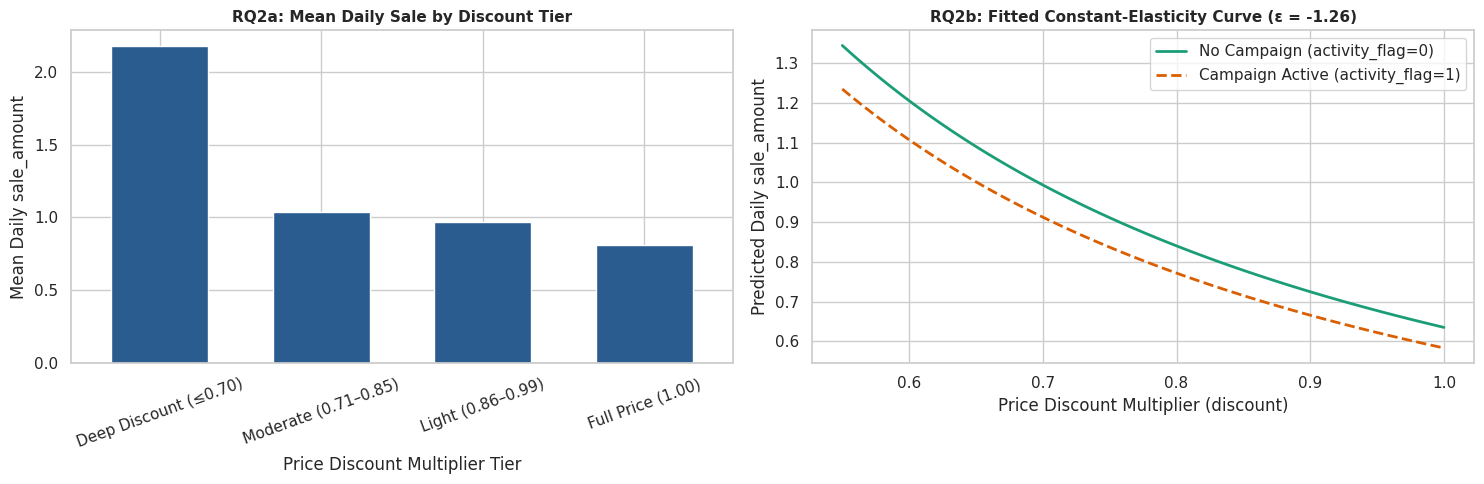

In [28]:
# ==============================================================================
# 4.2 RQ2: PROMOTIONAL DISCOUNTS, CAMPAIGNS & PRICE ELASTICITY
# ==============================================================================
import statsmodels.api as sm

print("=== 1. SALES & DISCOUNT BY PROMOTIONAL CAMPAIGN (activity_flag) ===")
promo_grp = df.groupby("activity_flag").agg(
    rows=("sale_amount", "count"),
    share_pct=("sale_amount", lambda s: len(s) / len(df) * 100),
    mean_sale=("sale_amount", "mean"),
    median_sale=("sale_amount", "median"),
    mean_discount=("discount", "mean"),
    discounted_share_pct=("discount", lambda s: (s < 1.0).mean() * 100),
    mean_stockout_hrs=("stock_hour6_22_cnt", "mean"),
)
promo_grp.index = ["No Campaign (0)", "Campaign Active (1)"]
display(promo_grp.round(4))

print("\n=== 2. SALES BY DISCOUNT TIERS ===")
df["discount_tier"] = pd.cut(
    df["discount"],
    bins=[-0.01, 0.70, 0.85, 0.9999, 1.01],
    labels=["Deep Discount (≤0.70)", "Moderate (0.71–0.85)", "Light (0.86–0.99)", "Full Price (1.00)"]
)
disc_grp = df.groupby("discount_tier", observed=False).agg(
    rows=("sale_amount", "count"),
    share_pct=("sale_amount", lambda s: len(s) / len(df) * 100),
    mean_sale=("sale_amount", "mean"),
    median_sale=("sale_amount", "median"),
    promo_rate_pct=("activity_flag", lambda s: s.mean() * 100),
    mean_stockout_hrs=("stock_hour6_22_cnt", "mean"),
)
display(disc_grp.round(4))

# Fit Linear vs. Constant-Elasticity (Log-Log) models on positive sale_amount & positive discount
reg_df = df[(df["sale_amount"] > 0) & (df["discount"] > 0)].copy()
reg_df["log_sale"] = np.log(reg_df["sale_amount"])
reg_df["log_discount"] = np.log(reg_df["discount"])
reg_df["disc_x_promo"] = reg_df["discount"] * reg_df["activity_flag"]
reg_df["disc_x_stock"] = reg_df["discount"] * reg_df["stock_hour6_22_cnt"]

# Model A: Linear demand response with interaction terms
X_lin = sm.add_constant(reg_df[["discount", "activity_flag", "stock_hour6_22_cnt", "disc_x_promo", "disc_x_stock"]])
m_lin = sm.OLS(reg_df["sale_amount"], X_lin).fit()

# Model B: Constant-elasticity (log-log) demand response
X_log = sm.add_constant(reg_df[["log_discount", "activity_flag", "stock_hour6_22_cnt"]])
m_log = sm.OLS(reg_df["log_sale"], X_log).fit()

print("\n=== 3. LINEAR VS. CONSTANT-ELASTICITY (LOG-LOG) MODEL SUMMARY ===")
print(f"Linear Model R²          : {m_lin.rsquared:.4f} | discount coef: {m_lin.params['discount']:.4f} (p={m_lin.pvalues['discount']:.2e})")
print(f"Linear activity_flag coef: {m_lin.params['activity_flag']:.4f} | disc x promo: {m_lin.params['disc_x_promo']:.4f} | disc x stock: {m_lin.params['disc_x_stock']:.4f}")
print(f"Log-Log Elasticity (b1)  : {m_log.params['log_discount']:.4f} (p={m_log.pvalues['log_discount']:.2e}) | Log-Log R²: {m_log.rsquared:.4f}")
print(f"Log-Log activity_flag    : {m_log.params['activity_flag']:.4f} (exp-1 lift: {(np.exp(m_log.params['activity_flag'])-1)*100:.2f}%)")

# Variance Inflation Factors (VIF) on linear predictors
X_vif = reg_df[["discount", "activity_flag", "stock_hour6_22_cnt"]].assign(const=1.0)
vif_rows = []
for col in ["discount", "activity_flag", "stock_hour6_22_cnt"]:
    others = [c for c in X_vif.columns if c != col]
    r2_other = sm.OLS(X_vif[col], X_vif[others]).fit().rsquared
    vif_val = 1.0 / max(1.0 - r2_other, 1e-8)
    vif_rows.append({"Predictor": col, "VIF": round(vif_val, 3)})
print("\n=== 4. MULTICOLLINEARITY CHECK (VIF) ===")
display(pd.DataFrame(vif_rows).set_index("Predictor"))

# --- Plot 4.2: Discount Tiers & Constant-Elasticity Curve ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.0))

ax1 = axes[0]
disc_grp["mean_sale"].plot(kind="bar", color="#2b5c8f", ax=ax1, width=0.6)
ax1.set_title("RQ2a: Mean Daily Sale by Discount Tier", fontsize=11, fontweight="bold")
ax1.set_xlabel("Price Discount Multiplier Tier")
ax1.set_ylabel("Mean Daily sale_amount")
ax1.tick_params(axis="x", rotation=20)

ax2 = axes[1]
grid_disc = np.linspace(0.55, 1.00, 100)
pred_log_nopro = np.exp(
    m_log.params["const"]
    + m_log.params["log_discount"] * np.log(grid_disc)
    + m_log.params["activity_flag"] * 0
    + m_log.params["stock_hour6_22_cnt"] * reg_df["stock_hour6_22_cnt"].mean()
)
pred_log_pro = np.exp(
    m_log.params["const"]
    + m_log.params["log_discount"] * np.log(grid_disc)
    + m_log.params["activity_flag"] * 1
    + m_log.params["stock_hour6_22_cnt"] * reg_df["stock_hour6_22_cnt"].mean()
)
ax2.plot(grid_disc, pred_log_nopro, label="No Campaign (activity_flag=0)", linewidth=2.0, color="#1b9e77")
ax2.plot(grid_disc, pred_log_pro, label="Campaign Active (activity_flag=1)", linewidth=2.0, linestyle="--", color="#d95f02")
ax2.set_title(f"RQ2b: Fitted Constant-Elasticity Curve (ε = {m_log.params['log_discount']:.2f})", fontsize=11, fontweight="bold")
ax2.set_xlabel("Price Discount Multiplier (discount)")
ax2.set_ylabel("Predicted Daily sale_amount")
ax2.legend()

plt.tight_layout()
plt.show()

## 4.3 RQ3: Calendar, Weather & Operational Unit Efficiency
**Research Question:** *How do calendar effects (`holiday_flag`, day of week) and weather conditions (`precpt`, `avg_temperature`, `avg_humidity`, `avg_wind_level`) relate to sales and stockouts, and how do management groups/categories compare in operational efficiency?*

- **Hypothesis ($H_3$):** Holidays/weekends and favourable weather shift demand and stockout incidence, while operating units (`management_group_id` / top categories) vary in how efficiently they convert operational exposure into realised sales with low daytime stockouts.
- **Method (BA & Industry 4.0 Alignment — L12–L16, L30–L35, L42–L49):**
  1. Test association between categorical demand/stockout states (`has_stockout`, `holiday_flag`, `activity_flag`) using a **Chi-square ($\chi^2$) contingency test** and **Cramér's $V$**.
  2. Fit a **Multiple Linear Regression** of `sale_amount` on calendar, weather, promotion, and stockout features.
  3. Compute a **Data Envelopment Analysis (DEA)-style efficiency benchmark** (input-oriented CCR/BCC linear program via `scipy.optimize.linprog` on aggregated `management_group_id` units: inputs = mean `stock_hour6_22_cnt` and `1 - discount` or operational load; output = mean `sale_amount`) to rank units and identify efficiency gaps.
- **Constraints & Scope:** `sale_amount` is globally normalised without explicit monetary costs or physical inventory quantities, so DEA scores serve as an illustrative relative efficiency benchmark across operational groups rather than audited financial efficiency.

=== 1. CHI-SQUARE TEST: holiday_flag VS. DAYTIME STOCKOUT (>0h) ===
Chi2 = 5.95, dof = 1, p = 1.47e-02, Cramer's V = 0.0026


has_stockout,0,1
holiday_flag,,
0,330215,260965
1,172668,137952



=== 2. MULTIPLE LINEAR REGRESSION (CALENDAR + WEATHER + OPS) ===
MLR R² = 0.2493 | Adj. R² = 0.2493


,Coef,Std_Err,t_stat,p_value
discount,-7.0503,0.0135,-521.6820,0.0
activity_flag,-1.2119,0.0036,-338.4860,0.0
stock_hour6_22_cnt,-0.0337,0.0003,-120.3892,0.0
holiday_flag,0.1059,0.0048,21.9300,0.0
is_weekend,0.1753,0.0051,34.5750,0.0
precpt,-0.0021,0.0005,-4.5411,0.0
avg_temperature,0.0062,0.0004,14.6974,0.0
avg_humidity,0.0050,0.0002,32.9811,0.0
avg_wind_level,-0.0666,0.0034,-19.3398,0.0



=== 3. INPUT-ORIENTED CCR DEA BY management_group_id ===


,mean_sale,mean_stockout,mean_discount,mean_precpt,CCR_Efficiency
management_group_id,,,,,
2,1.0746,3.4927,0.9447,4.0855,1.0000
6,1.1353,3.1623,0.8974,3.5370,1.0000
3,0.7840,2.5190,0.9664,4.0923,0.9039
0,0.9060,3.5575,0.9003,3.5121,0.7629
5,0.7020,3.0733,0.9196,3.9128,0.6545
4,0.5792,2.6938,0.8417,3.2157,0.5957
1,0.5388,2.6671,0.9469,3.6479,0.5792


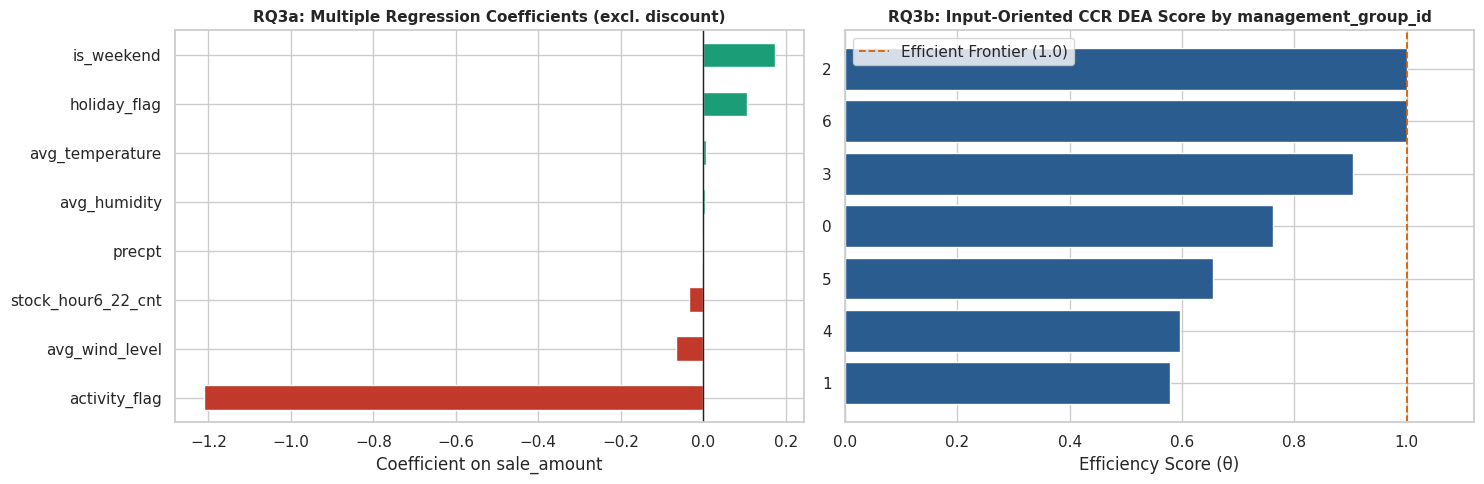

In [29]:
# ==============================================================================
# 4.3 RQ3: CALENDAR, WEATHER & OPERATIONAL UNIT EFFICIENCY (CHI-SQ, MLR, DEA)
# ==============================================================================
from scipy import stats
from scipy.optimize import linprog
import statsmodels.api as sm

# 1. Chi-square test of independence: holiday_flag vs. daytime stockout presence
df["has_stockout"] = (df["stock_hour6_22_cnt"] > 0).astype(int)
ct = pd.crosstab(df["holiday_flag"], df["has_stockout"])
chi2, p_val, dof, _ = stats.chi2_contingency(ct)
n_obs = ct.to_numpy().sum()
min_dim = min(ct.shape) - 1
cramers_v = np.sqrt(chi2 / (n_obs * max(min_dim, 1)))

print("=== 1. CHI-SQUARE TEST: holiday_flag VS. DAYTIME STOCKOUT (>0h) ===")
print(f"Chi2 = {chi2:.2f}, dof = {dof}, p = {p_val:.2e}, Cramer's V = {cramers_v:.4f}")
display(ct)

# 2. Multiple Linear Regression with calendar & weather features
mlr_df = df.copy()
mlr_df["is_weekend"] = mlr_df["dt"].dt.dayofweek.isin([5, 6]).astype(int)
mlr_cols = [
    "discount",
    "activity_flag",
    "stock_hour6_22_cnt",
    "holiday_flag",
    "is_weekend",
    "precpt",
    "avg_temperature",
    "avg_humidity",
    "avg_wind_level",
]
X_mlr = sm.add_constant(mlr_df[mlr_cols])
m_mlr = sm.OLS(mlr_df["sale_amount"], X_mlr).fit()

print("\n=== 2. MULTIPLE LINEAR REGRESSION (CALENDAR + WEATHER + OPS) ===")
print(f"MLR R² = {m_mlr.rsquared:.4f} | Adj. R² = {m_mlr.rsquared_adj:.4f}")
coef_table = pd.DataFrame({
    "Coef": m_mlr.params.drop("const"),
    "Std_Err": m_mlr.bse.drop("const"),
    "t_stat": m_mlr.tvalues.drop("const"),
    "p_value": m_mlr.pvalues.drop("const"),
})
display(coef_table.round(4))

# 3. Input-oriented CCR DEA across management_group_id
# Output y: mean sale_amount
# Inputs X: [mean stockout hours + 1, mean weather/promo load] (strictly positive for LP)
dea_src = (
    df.groupby("management_group_id")
    .agg(
        mean_sale=("sale_amount", "mean"),
        mean_stockout=("stock_hour6_22_cnt", "mean"),
        mean_discount=("discount", "mean"),
        mean_precpt=("precpt", "mean"),
    )
    .sort_index()
)

# Construct positive operational inputs (x1: stockout burden, x2: promo/rain exposure) and output (y: sales)
X_dea = np.column_stack([
    dea_src["mean_stockout"].to_numpy() + 0.1,
    (1.0 - dea_src["mean_discount"].to_numpy()) + 0.1 + 0.01 * dea_src["mean_precpt"].to_numpy(),
])
Y_dea = dea_src["mean_sale"].to_numpy().reshape(-1, 1)

def solve_ccr_dea_input(X, Y):
    """Input-oriented CCR efficiency score theta_k in (0, 1] for each DMU k."""
    n_dmu, m_inp = X.shape
    _, s_out = Y.shape
    scores = np.ones(n_dmu)
    for k in range(n_dmu):
        # Variables: [theta, lam_0, ..., lam_{n-1}]
        c = np.zeros(1 + n_dmu)
        c[0] = 1.0
        # Constraints:
        # 1) sum_j lam_j * X_{j,i} - theta * X_{k,i} <= 0  for each input i
        A_inp = np.zeros((m_inp, 1 + n_dmu))
        A_inp[:, 0] = -X[k, :]
        A_inp[:, 1:] = X.T
        b_inp = np.zeros(m_inp)

        # 2) -sum_j lam_j * Y_{j,r} <= -Y_{k,r}  for each output r
        A_out = np.zeros((s_out, 1 + n_dmu))
        A_out[:, 1:] = -Y.T
        b_out = -Y[k, :]

        A_ub = np.vstack([A_inp, A_out])
        b_ub = np.concatenate([b_inp, b_out])
        bounds = [(0.0, 1.0)] + [(0.0, None)] * n_dmu

        res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
        scores[k] = res.fun if res.success else np.nan
    return scores

dea_src["CCR_Efficiency"] = solve_ccr_dea_input(X_dea, Y_dea)
print("\n=== 3. INPUT-ORIENTED CCR DEA BY management_group_id ===")
display(dea_src.sort_values("CCR_Efficiency", ascending=False).round(4))

# --- Plot 4.3: Key MLR Coefficients & DEA Efficiency Scores ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.0))

plot_coefs = m_mlr.params.drop(["const", "discount"]).sort_values()
colors_coef = ["#c0392b" if v < 0 else "#1b9e77" for v in plot_coefs.values]
plot_coefs.plot(kind="barh", color=colors_coef, ax=axes[0])
axes[0].axvline(0, color="#222222", linewidth=1.0)
axes[0].set_title("RQ3a: Multiple Regression Coefficients (excl. discount)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Coefficient on sale_amount")

dea_plot = dea_src.sort_values("CCR_Efficiency", ascending=True)
axes[1].barh(dea_plot.index.astype(str), dea_plot["CCR_Efficiency"], color="#2b5c8f")
axes[1].set_xlim(0, 1.12)
axes[1].axvline(1.0, color="#d95f02", linestyle="--", linewidth=1.3, label="Efficient Frontier (1.0)")
axes[1].set_title("RQ3b: Input-Oriented CCR DEA Score by management_group_id", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Efficiency Score (θ)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4.4 RQ4: Category Co-Movement & Stockout-Aware Allocation Policy
**Research Question:** *Which top product categories co-occur frequently across store-days, and how can a linear optimization / allocation rule allocate replenishment capacity under stockout censoring?*

- **Hypothesis ($H_4$):** High-volume categories exhibit strong store-day co-occurrence (suitable for basket/assortment bundling via Apriori), and allocating order capacity proportional to stockout-adjusted demand (`sale_amount` scaled up by stockout censoring) improves expected fulfilment over unadjusted allocation.
- **Method (Industry 4.0 Alignment — W4_L4.5–L4.6, W5_L5.1–W5.2, W7_L7.1–L7.5, L28):**
  1. Run **Apriori-style frequent itemset & association rule mining** across store-days for the top 8 `first_category_id` groups with positive sales (`sale_amount > 0`).
  2. Formulate a **Linear Programming (LP) allocation model** (`scipy.optimize.linprog`) across top categories to allocate limited capacity toward higher uncensored demand and healthier price multipliers (`discount`) compared to a naive sales-share split.
- **Constraints & Scope:** Basket-level receipts are unavailable, so co-occurrence is evaluated at the `(store_id, dt)` level across active categories, and LP allocation is a normalised capacity-sharing model rather than a physical vehicle-routing or warehouse schedule.

=== 1. APRIORI ASSOCIATION RULES (n_store_days=79,342, min_support=0.05) ===


,antecedent,consequent,support,confidence,lift
16,8,21,0.2074,0.5640,1.2996
17,21,8,0.2074,0.4779,1.2996
10,8,10,0.2134,0.5804,1.2934
11,10,8,0.2134,0.4756,1.2934
32,8,18,0.1939,0.5272,1.2907
33,18,8,0.1939,0.4746,1.2907
15,20,8,0.2872,0.4491,1.2213
14,8,20,0.2872,0.7810,1.2213
0,4,8,0.3461,0.4313,1.1728
1,8,4,0.3461,0.9411,1.1728



=== 2. LP CAPACITY ALLOCATION (Total Capacity = 7.5063) ===


,mean_sale,mean_stockout_hrs,mean_discount,uncensored_demand,LP_Allocation,Naive_Sale_Share_Alloc
first_category_id,,,,,,
21,1.8498,3.1397,0.8588,2.0380,2.0380,1.6394
29,1.4521,4.0726,0.9366,1.6497,1.6497,1.2869
20,1.2388,3.1482,0.8797,1.3652,1.3652,1.0979
4,1.1711,3.2116,0.8903,1.2933,1.2933,1.0379
10,0.7315,3.5593,0.9426,0.8170,0.8170,0.6482
16,0.7446,3.2230,0.9173,0.8226,0.3431,0.6599
8,0.7020,2.8656,0.9163,0.7666,0.0000,0.6221
18,0.5800,2.7210,0.9317,0.6304,0.0000,0.5140


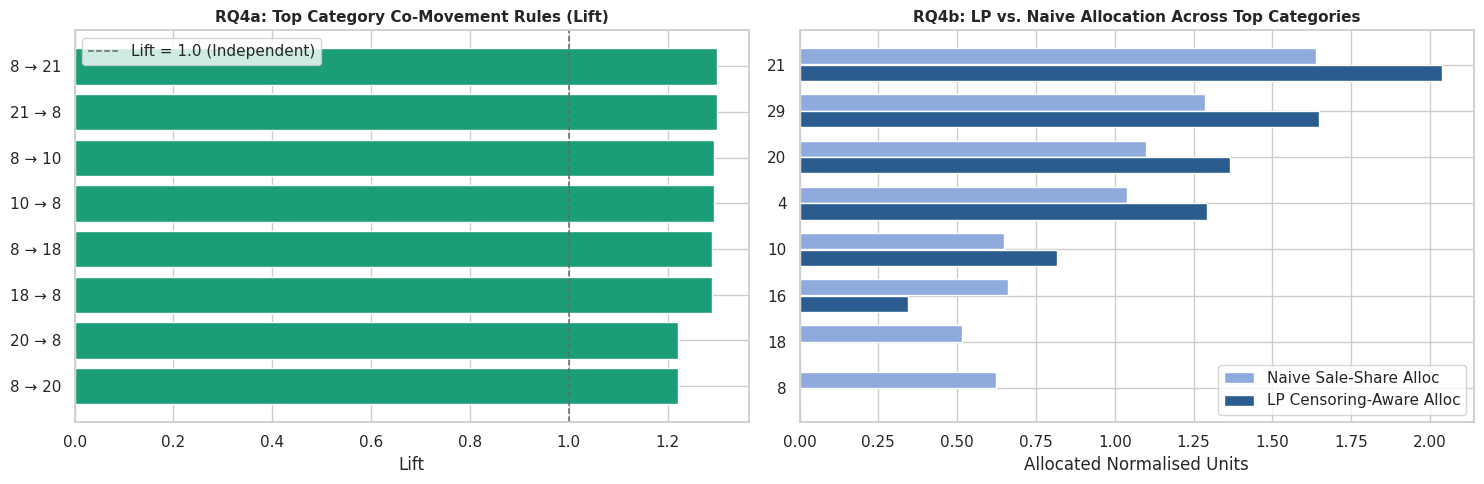

In [30]:
# ==============================================================================
# 4.4 RQ4: APRIORI CATEGORY CO-MOVEMENT & ALLOCATION OPTIMIZATION (LP)
# ==============================================================================
from itertools import combinations
from scipy.optimize import linprog

# 1. Frequent itemset & association rules (Apriori logic) across (store_id, dt)
top8_cats = (
    df.groupby("first_category_id")["sale_amount"]
    .count()
    .sort_values(ascending=False)
    .head(8)
    .index.tolist()
)

active_sub = df[(df["first_category_id"].isin(top8_cats)) & (df["sale_amount"] > 0)]
baskets = active_sub.groupby(["store_id", "dt"])["first_category_id"].unique()
n_baskets = len(baskets)

cnt_1 = {}
cnt_2 = {}
for cats in baskets:
    s_cats = sorted(set(int(c) for c in cats))
    for c in s_cats:
        cnt_1[c] = cnt_1.get(c, 0) + 1
    for a, b in combinations(s_cats, 2):
        cnt_2[(a, b)] = cnt_2.get((a, b), 0) + 1

min_sup = 0.05  # 5% minimum support
freq_1 = {k: v / n_baskets for k, v in cnt_1.items() if (v / n_baskets) >= min_sup}
rules = []
for (a, b), c_ab in cnt_2.items():
    sup_ab = c_ab / n_baskets
    if sup_ab >= min_sup and a in freq_1 and b in freq_1:
        sup_a = freq_1[a]
        sup_b = freq_1[b]
        conf_ab = sup_ab / sup_a
        lift_ab = conf_ab / sup_b
        rules.append({"antecedent": a, "consequent": b, "support": sup_ab, "confidence": conf_ab, "lift": lift_ab})
        conf_ba = sup_ab / sup_b
        lift_ba = conf_ba / sup_a
        rules.append({"antecedent": b, "consequent": a, "support": sup_ab, "confidence": conf_ba, "lift": lift_ba})

rules_df = pd.DataFrame(rules).sort_values("lift", ascending=False)
print(f"=== 1. APRIORI ASSOCIATION RULES (n_store_days={n_baskets:,}, min_support={min_sup}) ===")
display(rules_df.head(10).round(4))

# 2. Linear Programming (LP) allocation across top 8 categories
cat_alloc = (
    df[df["first_category_id"].isin(top8_cats)]
    .groupby("first_category_id")
    .agg(
        mean_sale=("sale_amount", "mean"),
        mean_stockout_hrs=("stock_hour6_22_cnt", "mean"),
        mean_discount=("discount", "mean"),
    )
)
stockout_frac = (cat_alloc["mean_stockout_hrs"] / 17.0).clip(0.0, 0.85)
cat_alloc["uncensored_demand"] = cat_alloc["mean_sale"] / (1.0 - 0.5 * stockout_frac)

total_cap = 0.80 * cat_alloc["uncensored_demand"].sum()
n_c = len(cat_alloc)

weights = (cat_alloc["uncensored_demand"] * cat_alloc["mean_discount"]).to_numpy()
c_obj = -weights

A_ub = np.ones((1, n_c))
b_ub = np.array([total_cap])
bounds = [(0.0, float(d)) for d in cat_alloc["uncensored_demand"]]

lp_res = linprog(c_obj, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
cat_alloc["LP_Allocation"] = lp_res.x
cat_alloc["Naive_Sale_Share_Alloc"] = total_cap * (cat_alloc["mean_sale"] / cat_alloc["mean_sale"].sum())

print(f"\n=== 2. LP CAPACITY ALLOCATION (Total Capacity = {total_cap:.4f}) ===")
display(cat_alloc.sort_values("LP_Allocation", ascending=False).round(4))

# --- Plot 4.4: Top Co-Movement Lift & LP vs Naive Allocation ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.0))

top_r = rules_df.head(8).copy()
top_r["rule_label"] = top_r["antecedent"].astype(str) + " → " + top_r["consequent"].astype(str)
axes[0].barh(top_r["rule_label"][::-1], top_r["lift"][::-1], color="#1b9e77")
axes[0].axvline(1.0, color="#666666", linestyle="--", linewidth=1.1, label="Lift = 1.0 (Independent)")
axes[0].set_title("RQ4a: Top Category Co-Movement Rules (Lift)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Lift")
axes[0].legend()

alloc_plot = cat_alloc.sort_values("LP_Allocation", ascending=True)
idx_pos = np.arange(len(alloc_plot))
axes[1].barh(idx_pos + 0.18, alloc_plot["Naive_Sale_Share_Alloc"], height=0.35, color="#8faadc", label="Naive Sale-Share Alloc")
axes[1].barh(idx_pos - 0.18, alloc_plot["LP_Allocation"], height=0.35, color="#2b5c8f", label="LP Censoring-Aware Alloc")
axes[1].set_yticks(idx_pos)
axes[1].set_yticklabels(alloc_plot.index.astype(str))
axes[1].set_title("RQ4b: LP vs. Naive Allocation Across Top Categories", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Allocated Normalised Units")
axes[1].legend()

plt.tight_layout()
plt.show()